In [5]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch

signals = pd.read_parquet('../data/processed/signals_PVS1_left.parquet')
windows = pd.read_csv('../data/processed/windows_PVS1_left.csv')

valid_ids = windows[windows['valid']].index
win_id = valid_ids[10]

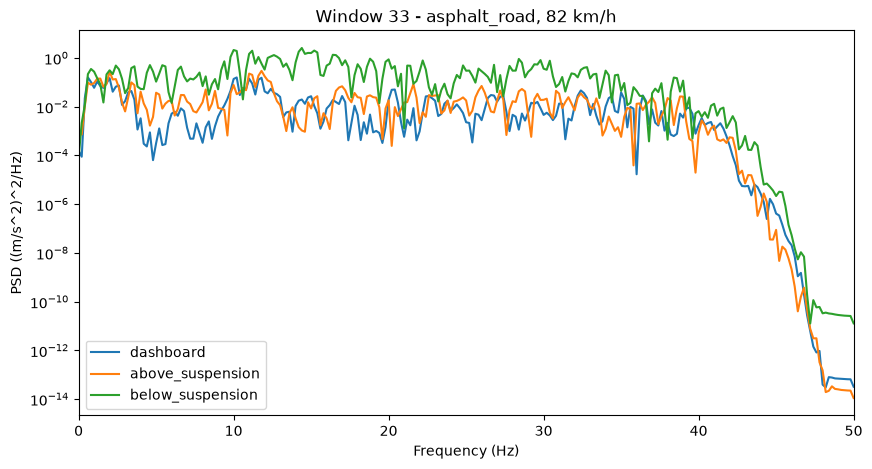

In [6]:
seg = signals[signals['window'] == win_id]
surface = windows.loc[win_id, 'surface']
speed_kmh = windows.loc[win_id, 'speed_mean']*3.6

positions = ['dashboard', 'above_suspension', 'below_suspension']
fs = 100

fig, ax = plt.subplots(figsize=(10,5))
for pos in positions:
    f, Pxx = welch(seg[f'acc_z_{pos}_filt'].to_numpy(), fs = fs, nperseg = 500)
    ax.semilogy(f, Pxx, label=pos)

ax.set_xlim(0,50)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD ((m/s^2)^2/Hz)')
ax.set_title(f'Window {win_id} - {surface}, {speed_kmh:.0f} km/h')
ax.legend()
plt.show()

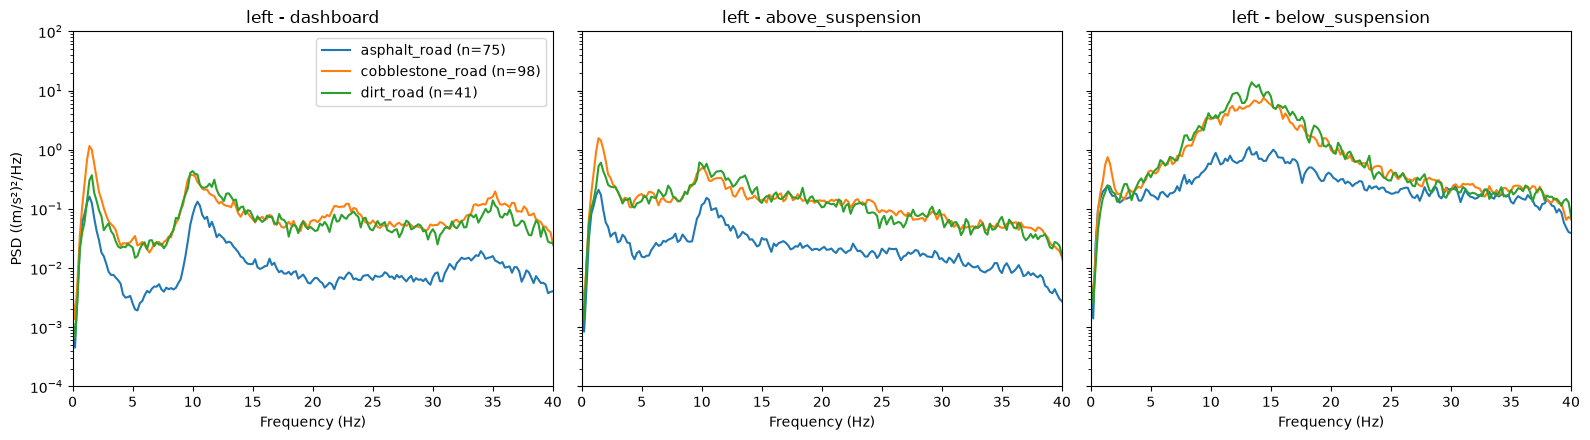

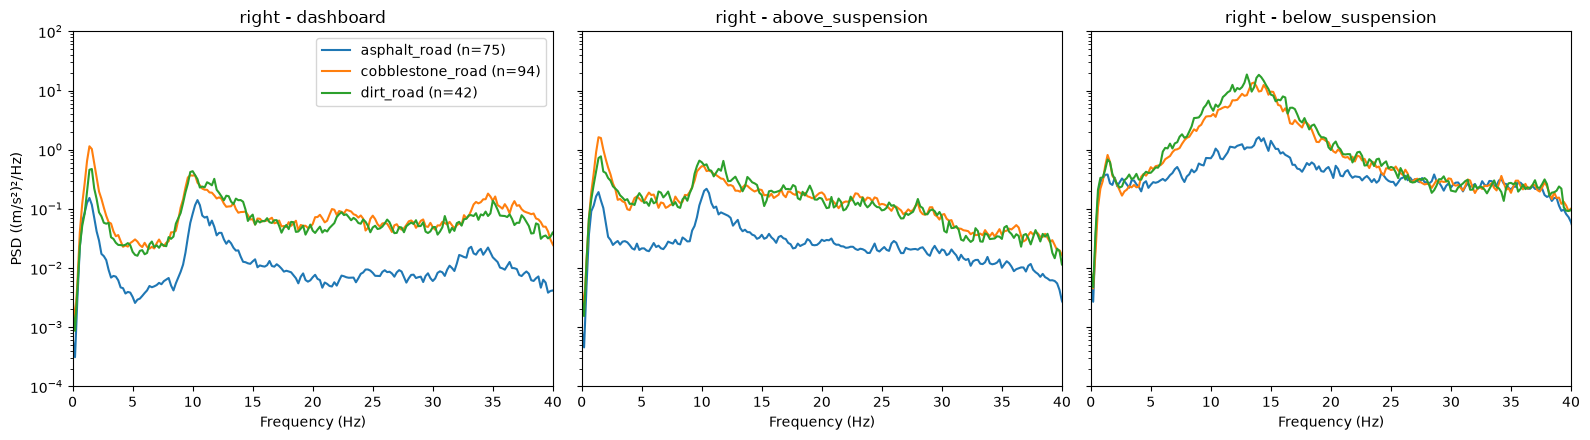

In [7]:
from src.spectral import mean_psd

data={}
for side in ['left', 'right']:
    signals = pd.read_parquet(f'../data/processed/signals_PVS1_{side}.parquet')
    windows = pd.read_csv(f'../data/processed/windows_PVS1_{side}.csv', index_col='window')
    data[side] = (signals, windows)

surfaces = ['asphalt_road', 'cobblestone_road', 'dirt_road']

for side, (signals, windows) in data.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, pos in zip(axes, positions):
        for surf in surfaces:
            ids = windows[windows['valid'] & (windows['surface'] == surf)].index
            f, P = mean_psd(signals, ids, f'acc_z_{pos}_filt')
            ax.semilogy(f, P, label = f'{surf} (n={len(ids)})')
        ax.set_title(f'{side} - {pos}')
        ax.set_title(f'{side} - {pos}')
        ax.set_xlim(0, 40)
        ax.set_xlabel('Frequency (Hz)')
    axes[0].set_ylim(1e-4, 1e2)
    axes[0].set_ylabel('PSD ((m/s²)²/Hz)')
    axes[0].legend()
    plt.tight_layout()
    plt.show()

In [19]:
from src.spectral import peak_frequency, band_rms

bands = {'Body': (0.5, 3),
         'wheel': (8, 20),
         'high': (20, 40)}

rows = []
for side, (signals, windows) in data.items():
    for pos in positions:
        for surf in surfaces:
            ids = windows[windows['valid'] & (windows['surface'] == surf)].index
            f, P = mean_psd(signals, ids, f'acc_z_{pos}_filt')

            row = {'side': side, 'position': pos, 'surface': surf, 'n_windows': len(ids)}
            for band, (lo, hi) in bands.items():
                row[f'{band}_peak_hz'] = peak_frequency(f, P, lo, hi)
                row[f'{band}_rms'] = band_rms(f, P, lo, hi)
            rows.append(row)

results = pd.DataFrame(rows)
display(results)


,side,position,surface,n_windows,Body_peak_hz,Body_rms,wheel_peak_hz,wheel_rms,high_peak_hz,high_rms
0,left,dashboard,asphalt_road,75,1.4,0.389935,10.4,0.553553,34.0,0.414851
1,left,dashboard,cobblestone_road,98,1.4,0.968436,9.8,1.171671,35.2,1.258001
2,left,dashboard,dirt_road,41,1.6,0.554722,10.0,1.251097,35.0,1.081322
3,left,above_suspension,asphalt_road,75,1.4,0.467711,10.4,0.725353,22.6,0.530044
4,left,above_suspension,cobblestone_road,98,1.4,1.228976,10.0,1.579713,23.0,1.235429
5,left,above_suspension,dirt_road,41,1.6,0.833614,9.8,1.729894,21.4,1.166236
6,left,below_suspension,asphalt_road,75,1.4,0.637407,13.2,2.683576,20.0,1.929910
7,left,below_suspension,cobblestone_road,98,1.4,0.865692,14.4,6.578053,20.6,2.594467
8,left,below_suspension,dirt_road,41,2.8,0.661545,13.4,7.755495,20.6,2.552735
9,right,dashboard,asphalt_road,75,1.4,0.387249,10.4,0.564181,33.2,0.431653


In [10]:
for side, (signals, windows) in data.items():
    windows['speed_kmh'] = windows['speed_mean'] * 3.6
    windows['speed_band'] = pd.cut(windows['speed_kmh'], bins=[10, 40, 60, 200], labels=['10-40', '40-60', '>60'])

w = data['left'][1]
print(w[w['valid']].groupby(['surface', 'speed_band'], observed=True).size())

surface           speed_band
asphalt_road      10-40          1
                  40-60          4
                  >60           70
cobblestone_road  10-40         98
dirt_road         10-40         41
dtype: int64


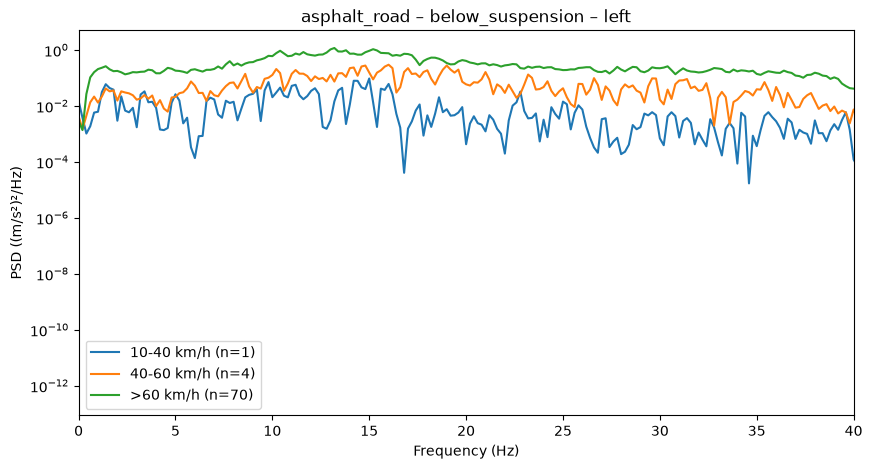

In [11]:
surf = 'asphalt_road'
pos = 'below_suspension'
signals, windows = data['left']

fig, ax = plt.subplots(figsize=(10, 5))
for band in ['10-40', '40-60', '>60']:
    ids = windows[windows['valid'] & (windows['surface'] == surf) & (windows['speed_band'] == band)].index
    if len(ids) == 0:
        continue
    f, P = mean_psd(signals, ids, f'acc_z_{pos}_filt')
    ax.semilogy(f, P, label=f'{band} km/h (n={len(ids)})')

ax.set_xlim(0, 40)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD ((m/s²)²/Hz)')
ax.set_title(f'{surf} – {pos} – left')
ax.legend()
plt.show()

In [12]:
print(w[w['valid']].groupby('surface')['speed_kmh'].describe())

                  count       mean        std        min        25%  \
surface                                                               
asphalt_road       75.0  77.086782  12.615007  22.479491  69.726833   
cobblestone_road   98.0  21.832147   6.105287  10.623566  16.928586   
dirt_road          41.0  24.070294   5.744132  13.466189  19.329842   

                        50%        75%        max  
surface                                            
asphalt_road      80.196563  85.295521  95.745582  
cobblestone_road  22.632377  25.976445  38.585083  
dirt_road         23.293904  29.813508  33.738786  


In [13]:
SPEED_BINS = {
    'asphalt_road': [60, 70, 80, 90, 100],
    'cobblestone_road': [10, 20, 30, 40],
    'dirt_road': [10, 20, 30, 40],
}

for side, (signals, windows) in data.items():
    windows['speed_band'] = None
    for surf, bins in SPEED_BINS.items():
        mask = windows['surface'] == surf
        windows.loc[mask, 'speed_band'] = pd.cut(windows.loc[mask, 'speed_kmh'], bins=bins).astype(object)

w = data['left'][1]
print(w[w['valid']].groupby(['surface', 'speed_band']).size())

surface           speed_band
asphalt_road      (60, 70]      15
                  (70, 80]      17
                  (80, 90]      27
                  (90, 100]     11
cobblestone_road  (10, 20]      37
                  (20, 30]      54
                  (30, 40]       7
dirt_road         (10, 20]      12
                  (20, 30]      19
                  (30, 40]      10
dtype: int64


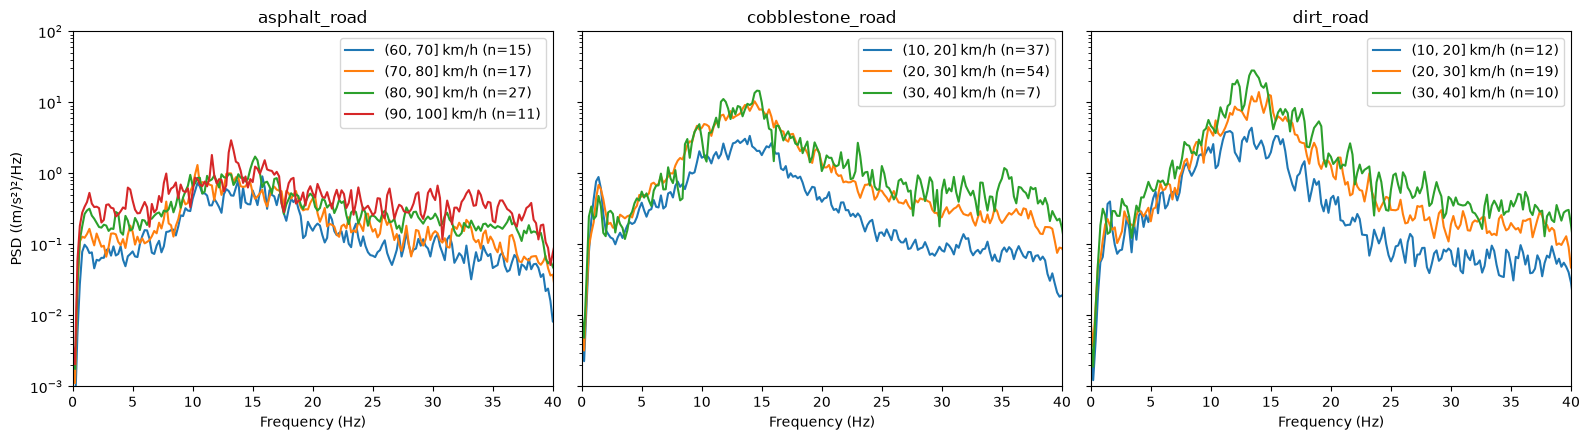

In [14]:
pos = 'below_suspension'
signals, windows = data['left']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, surf in zip(axes, SPEED_BINS):
    sub = windows[windows['valid'] & (windows['surface'] == surf)]
    for band, grp in sub.groupby('speed_band'):
        if len(grp) < 5:
            continue
        f, P = mean_psd(signals, grp.index, f'acc_z_{pos}_filt')
        ax.semilogy(f, P, label=f'{band} km/h (n={len(grp)})')
    ax.set_title(surf)
    ax.set_xlim(0, 40)
    ax.set_ylim(1e-3, 1e2)
    ax.set_xlabel('Frequency (Hz)')
    ax.legend()
axes[0].set_ylabel('PSD ((m/s²)²/Hz)')
plt.tight_layout()
plt.show()

In [26]:
rows = []
for side, (signals, windows) in data.items():
    for surf in SPEED_BINS:
        sub = windows[windows['valid'] & (windows['surface'] == surf)]
        for band, grp in sub.groupby('speed_band'):
            if len(grp) < 5:
                continue
            row = {'side': side, 'surface': surf, 'speed_band': band, 'n_windows': len(grp)}

            # wheel hop: below the suspension
            f, P = mean_psd(signals, grp.index, 'acc_z_below_suspension_filt')
            row['wheel_peak_hz'] = peak_frequency(f, P, *bands['wheel'])
            row['wheel_rms'] = band_rms(f, P, *bands['wheel'])

            # body mode: above the suspension
            f, P = mean_psd(signals, grp.index, 'acc_z_above_suspension_filt')
            row['body_peak_hz'] = peak_frequency(f, P, *bands['Body'])
            row['body_rms'] = band_rms(f, P, *bands['Body'])

            rows.append(row)

speed_results = pd.DataFrame(rows)
display(speed_results)

,side,surface,speed_band,n_windows,wheel_peak_hz,wheel_rms,body_peak_hz,body_rms
0,left,asphalt_road,"(60, 70]",15,15.8,2.212322,1.6,0.361110
1,left,asphalt_road,"(70, 80]",17,10.4,2.609189,1.4,0.434700
2,left,asphalt_road,"(80, 90]",27,15.2,2.915376,1.2,0.512112
3,left,asphalt_road,"(90, 100]",11,13.2,3.229091,1.4,0.582884
4,left,cobblestone_road,"(10, 20]",37,14.0,4.381567,1.4,1.275845
5,left,cobblestone_road,"(20, 30]",54,14.4,7.580152,1.6,1.233212
6,left,cobblestone_road,"(30, 40]",7,14.6,7.814233,1.4,0.899663
7,left,dirt_road,"(10, 20]",12,13.4,4.758377,1.6,0.908629
8,left,dirt_road,"(20, 30]",19,14.0,7.829466,2.0,0.785691
9,left,dirt_road,"(30, 40]",10,13.4,10.147117,1.8,0.827963


In [27]:
rows = []
for side, (signals, windows) in data.items():
    for surf in SPEED_BINS:
        sub = windows[windows['valid'] & (windows['surface'] == surf)]
        for band, grp in sub.groupby('speed_band'):
            if len(grp) < 5:
                continue
            for pos in positions:
                f, P = mean_psd(signals, grp.index, f'acc_z_{pos}_filt')
                row = {'side': side, 'surface': surf, 'speed_band': band, 'position': pos, 'n_windows': len(grp)}
                for b, (lo, hi) in bands.items():
                    row[f'{b}_peak_hz'] = peak_frequency(f, P, lo, hi)
                    row[f'{b}_rms'] = band_rms(f, P, lo, hi)
                rows.append(row)

speed_results = pd.DataFrame(rows)
display(speed_results)

,side,surface,speed_band,position,n_windows,Body_peak_hz,Body_rms,wheel_peak_hz,wheel_rms,high_peak_hz,high_rms
0,left,asphalt_road,"(60, 70]",dashboard,15,1.6,0.301944,10.4,0.543672,32.8,0.399921
1,left,asphalt_road,"(60, 70]",above_suspension,15,1.6,0.361110,10.4,0.688504,27.8,0.488245
2,left,asphalt_road,"(60, 70]",below_suspension,15,1.0,0.413825,15.8,2.212322,21.4,1.336013
3,left,asphalt_road,"(70, 80]",dashboard,17,1.6,0.335653,10.4,0.596273,34.0,0.447022
4,left,asphalt_road,"(70, 80]",above_suspension,17,1.4,0.434700,10.4,0.741487,20.8,0.497997
5,left,asphalt_road,"(70, 80]",below_suspension,17,1.4,0.527948,10.4,2.609189,20.2,1.690140
6,left,asphalt_road,"(80, 90]",dashboard,27,1.4,0.445405,10.6,0.561729,34.6,0.419178
7,left,asphalt_road,"(80, 90]",above_suspension,27,1.2,0.512112,10.6,0.750491,22.6,0.557844
8,left,asphalt_road,"(80, 90]",below_suspension,27,1.4,0.722678,15.2,2.915376,20.0,2.114423
9,left,asphalt_road,"(90, 100]",dashboard,11,1.4,0.480132,11.0,0.560299,34.0,0.379421


## Part 3 – Conclusions (PVS 1)

1. **Vibration modes:** the body (sprung-mass) mode appears at 1.2–1.8 Hz above the suspension and at the dashboard, with no clear dependence on speed or surface. The wheel-hop (unsprung-mass) mode appears below the suspension at 13–16 Hz; isolated values of ~10.4 Hz on asphalt result from peak picking on a broad, flat hump rather than a physical shift.
2. **Speed:** within each surface, the wheel-band RMS below the suspension increases with speed (cobblestone, left: 4.4 → 7.6 → 7.8 m/s² from 10–20 to 30–40 km/h; dirt: 4.8 → 7.8 → 10.1 m/s²), while the modal frequencies stay roughly constant.
3. **Surface:** surface type dominates over speed. Asphalt at 60–100 km/h (2.2–3.9 m/s² below the suspension) remains below cobblestone and dirt at 10–40 km/h (4.4–11.7 m/s²).
4. **Cobblestone vs dirt (20–30 km/h, left):** similar wheel-band input below the suspension (7.6 vs 7.8 m/s²), but cobblestone excites the body mode more strongly (1.23 vs 0.79 m/s² above the suspension) and transmits more high-frequency vibration to the dashboard (1.43 vs 1.13 m/s² in 20–40 Hz).
5. **Vehicle-related peaks:** a dashboard peak at ~35 Hz appears on all surfaces and speeds, suggesting a structural, engine or sensor-mount mode rather than road excitation. Above the suspension, the wheel-band maximum is at ~10 Hz instead of 13–16 Hz; to be investigated with the transmissibility analysis (Part 4).
6. **Consistency and limitations:** left and right sides give consistent results. Speed and surface are confounded in this trip (cobblestone and dirt only at 10–40 km/h, asphalt above 60 km/h), so speed effects can only be compared within each surface. Some speed bands contain few windows (n = 7–11), and the frequency resolution is 0.2 Hz.